# **Task 4: Generalization and Overfitting in Two-Layer Neural Networks.**

This notebook studies the training dynamics discussed by Montanari and Urbani (2025). The experiment uses a nonlinear single-index return-generating process and a two-layer ReLU network. We track training error, OOS error, OOS $R^2$, OOS Sharpe ratio, and a second-layer $\ell_1$ complexity measure over training time.


## I. Environment setup and imports

Reusable configuration, data generation, and neural-network routines are imported from `src`.

In [16]:
import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Resolve the repository root from either workspace or notebooks/ execution.
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Reload local modules so an active notebook kernel picks up source changes.
import src.config
import src.dgp
import src.models
importlib.reload(src.config)
importlib.reload(src.dgp)
importlib.reload(src.models)
import src
importlib.reload(src)
import src.plotting as plot
importlib.reload(plot)

from src import (
    FIG_DIR,
    RESULT_DIR,
    SEED,
    TASK4_DEFAULTS,
    build_two_layer_net,
    generate_nonlinear_single_index_data,
    get_torch_device,
    seed_torch,
    train_two_layer_network,
)

DEVICE = get_torch_device()
print("Device:", DEVICE)

D = TASK4_DEFAULTS["D"]
T_train = TASK4_DEFAULTS["T_train"]
T_test = TASK4_DEFAULTS["T_test"]
NOISE_STD = TASK4_DEFAULTS["noise_std"]
WIDTH = TASK4_DEFAULTS["width"]
LEARNING_RATE = TASK4_DEFAULTS["learning_rate"]
BATCH_SIZE = TASK4_DEFAULTS["batch_size"]
N_EPOCHS = TASK4_DEFAULTS["n_epochs"]

RESULT_PATH = PROJECT_ROOT / RESULT_DIR
FIG_PATH = PROJECT_ROOT / FIG_DIR
RESULT_PATH.mkdir(parents=True, exist_ok=True)
FIG_PATH.mkdir(parents=True, exist_ok=True)

Device: cpu


## II. Non-linear DGP

We use the nonlinear single-index structure studied by Montanari and Urbani:

$$
R_{t+1}=\phi(U^\top S_t)+\epsilon_{t+1},
\qquad S_t\sim N(0,I_d).
$$

For this finite-sample experiment, we set $k=1$ and use $\phi(z)=z+z^3/6$. The latent direction $U$ is fixed across the training and test samples.

In [17]:
# Generate one latent direction shared by the training and test samples.
rng = np.random.default_rng(SEED)
U = rng.normal(size=D)
U = U / np.linalg.norm(U)

X_train, R_train = generate_nonlinear_single_index_data(
    T_train,
    D,
    U,
    noise_std=NOISE_STD,
    seed=SEED,
)
X_test, R_test = generate_nonlinear_single_index_data(
    T_test,
    D,
    U,
    noise_std=NOISE_STD,
    seed=SEED + 1,
)

print("Training set:", X_train.shape, R_train.shape)
print("Test set:", X_test.shape, R_test.shape)

Training set: (2000, 100) (2000,)
Test set: (5000, 100) (5000,)


## III. Model

### Two-layer neural network

The two-layer ReLU network is implemented in `src.models` and deliberately overparameterized relative to the training sample.

### Evaluation and training

The OOS timing strategy uses $\pi_t=\hat R_t$, giving realized timing return $R_t^\pi=\hat R_tR_t$. We report the same uncentered Sharpe convention used elsewhere in the project:

$$
SR=\frac{\mathbb E[R^\pi]}{\sqrt{\mathbb E[(R^\pi)^2]}}.
$$

The evaluation metrics, complexity measure, and training loop are implemented in `src.models`.

## IV. Experiment

In [18]:
seed_torch(SEED)
model = build_two_layer_net(D, WIDTH, DEVICE)

history = train_two_layer_network(
    model=model,
    X_train=X_train,
    R_train=R_train,
    X_test=X_test,
    R_test=R_test,
    epochs=N_EPOCHS,
    batch_size=BATCH_SIZE,
    lr=LEARNING_RATE,
    device=DEVICE,
    seed=SEED,
)

history.head()

,epoch,train_mse,test_mse,test_r2,test_return,test_sharpe,complexity
0,1,15.577686,2.668453,-0.027260,-0.017416,-0.059432,8.125415
1,2,15.461950,2.601209,-0.001373,0.015970,0.053980,8.081639
2,3,15.349856,2.536803,0.023421,0.048908,0.152440,8.066293
3,4,15.240572,2.472054,0.048347,0.081484,0.232778,8.085425
4,5,15.132059,2.409392,0.072469,0.114179,0.288487,8.128933


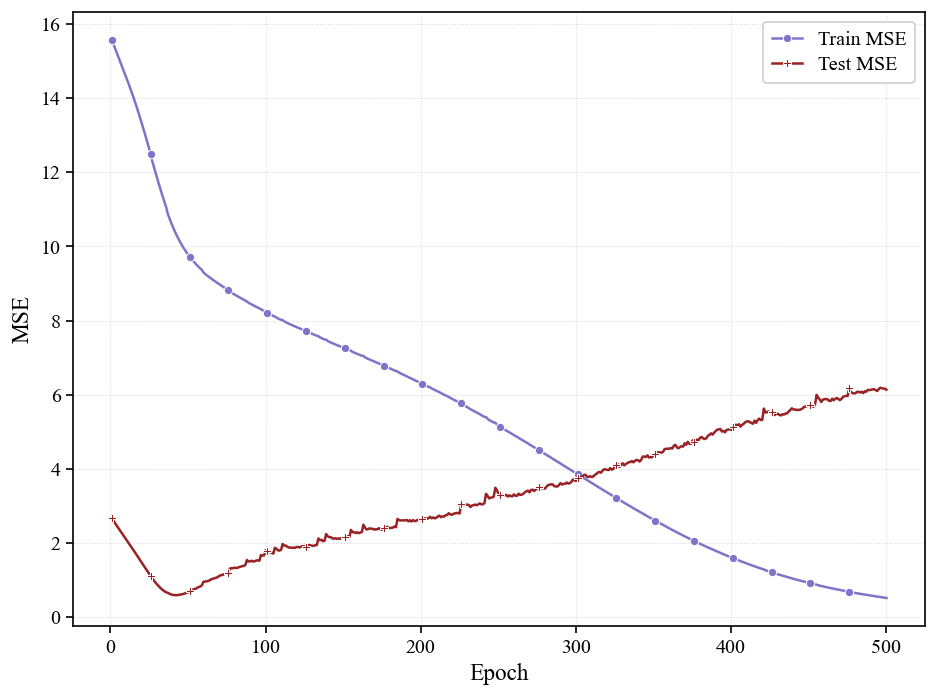

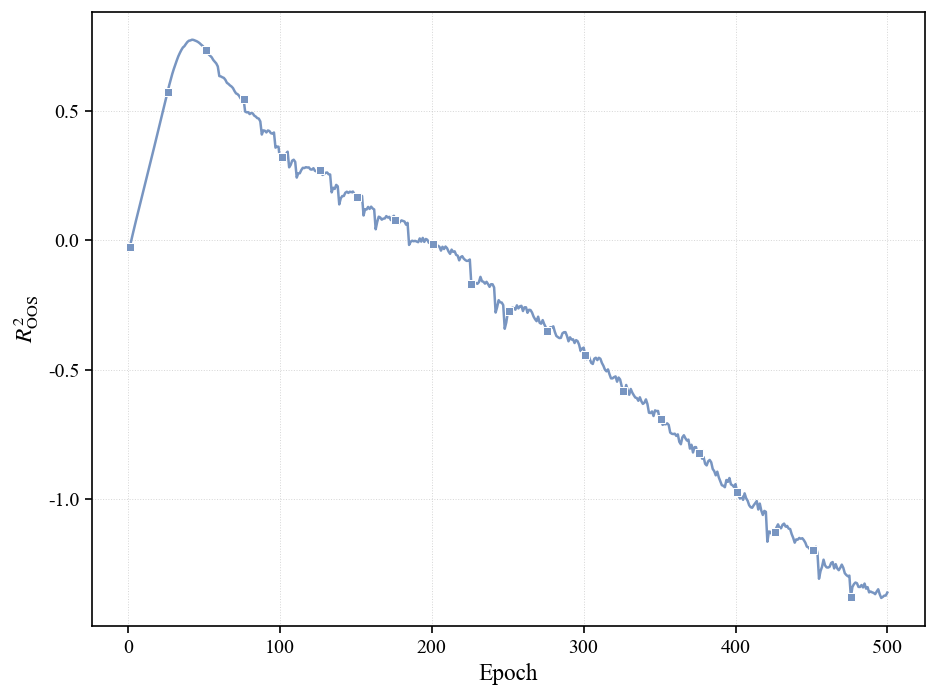

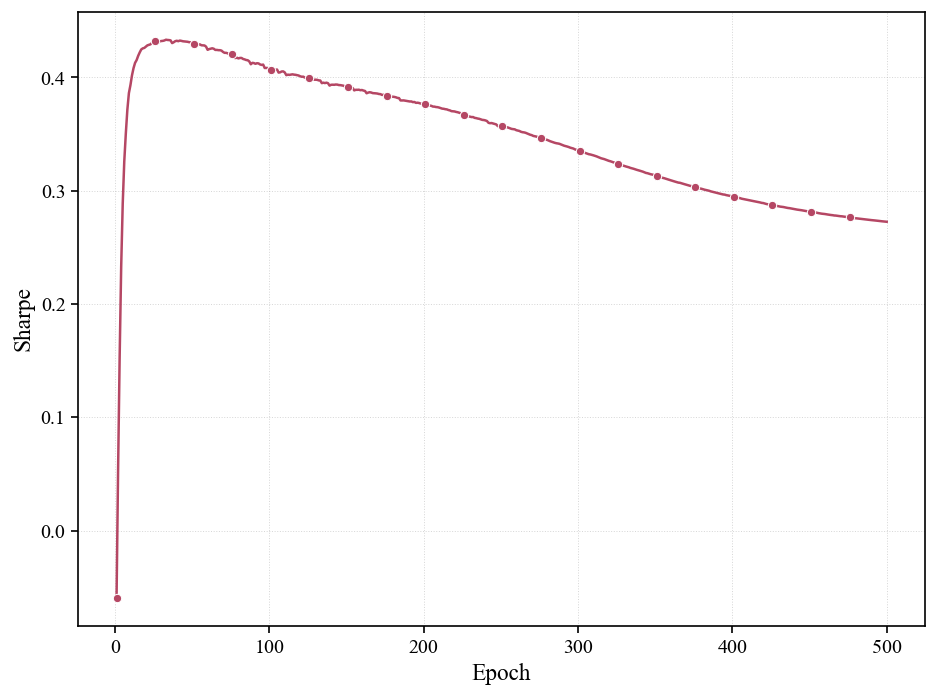

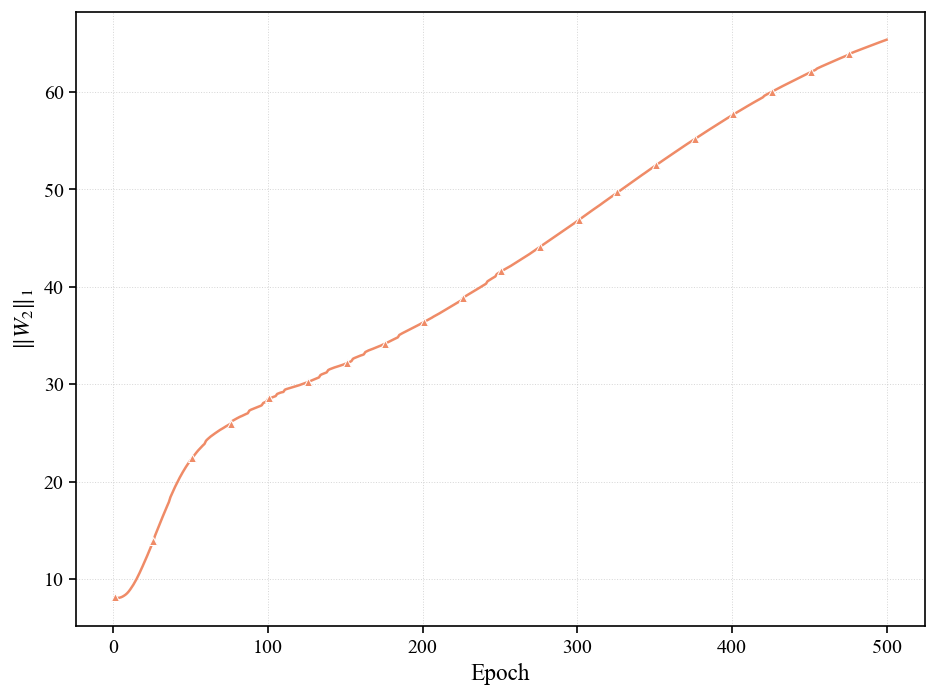

In [19]:
plot.plot_task4_training_dynamics(history, FIG_PATH)
plt.show()

## V. Compare the best OOS stopping point with the final model

In [20]:
# Compare peak OOS Sharpe and R2 epochs with the final training epoch.
best_sharpe_row = history.loc[history["test_sharpe"].idxmax()]
best_r2_row = history.loc[history["test_r2"].idxmax()]
final_row = history.iloc[-1]

comparison = pd.DataFrame({
    "Metric": [
        "Epoch",
        "Train MSE",
        "OOS MSE",
        "OOS R2",
        "OOS Sharpe",
        "Complexity",
    ],
    "Best Sharpe Epoch": [
        best_sharpe_row["epoch"],
        best_sharpe_row["train_mse"],
        best_sharpe_row["test_mse"],
        best_sharpe_row["test_r2"],
        best_sharpe_row["test_sharpe"],
        best_sharpe_row["complexity"],
    ],
    "Final Epoch": [
        final_row["epoch"],
        final_row["train_mse"],
        final_row["test_mse"],
        final_row["test_r2"],
        final_row["test_sharpe"],
        final_row["complexity"],
    ],
})

comparison

,Metric,Best Sharpe Epoch,Final Epoch
0,Epoch,33.000000,500.000000
1,Train MSE,11.443222,0.514969
2,OOS MSE,0.754174,6.132371
3,OOS R2,0.709670,-1.360745
4,OOS Sharpe,0.433248,0.272567
5,Complexity,16.797491,65.371117


In [21]:
# Save epoch-level metrics and the stopping-point comparison.
history.to_csv(RESULT_PATH / "task4_training_dynamics.csv", index=False)
comparison.to_csv(RESULT_PATH / "task4_stopping_comparison.csv", index=False)

print("Saved Task 4 results and figure.")

Saved Task 4 results and figure.
